In [1]:
from pathlib import Path
from ultralytics import YOLO

MODEL_PATH = Path("../models/yolo26n_1280_best.pt")
DATA_DIR = Path("../data/yolo_dataset")
VAL_IMAGES = DATA_DIR / "images" / "val"
VAL_LABELS = DATA_DIR / "labels" / "val"

IMG_W, IMG_H = 1360, 800
IMGSZ = 1280
CONF = 0.25
IOU_MATCH = 0.5

model = YOLO(MODEL_PATH)
val_images = sorted(VAL_IMAGES.glob("*.png"))
print(len(val_images))

134


In [2]:
img_path = val_images[0]
results = model.predict(img_path, imgsz=IMGSZ, conf=CONF, verbose=False)
r = results[0]

print(img_path.name)
print(r.boxes.xyxy.tolist())
print(r.boxes.conf.tolist())

00000.png
[[775.3641357421875, 411.4339599609375, 814.5415649414062, 445.2090148925781]]
[0.8803009390830994]


In [3]:
label_path = VAL_LABELS / f"{img_path.stem}.txt"
print(label_path.read_text())

0 0.584191 0.535625 0.030147 0.043750


In [4]:
def load_true_boxes(label_path):
    boxes = []
    for line in label_path.read_text().splitlines():
        _, xc, yc, w, h = line.split()
        xc, w = float(xc) * IMG_W, float(w) * IMG_W
        yc, h = float(yc) * IMG_H, float(h) * IMG_H
        boxes.append((xc - w / 2, yc - h / 2, xc + w / 2, yc + h / 2))
    return boxes

In [5]:
def iou(a, b):
    left = max(a[0], b[0])
    top = max(a[1], b[1])
    right = min(a[2], b[2])
    bottom = min(a[3], b[3])

    inter = max(0, right - left) * max(0, bottom - top)
    area_a = (a[2] - a[0]) * (a[3] - a[1])
    area_b = (b[2] - b[0]) * (b[3] - b[1])
    union = area_a + area_b - inter
    return inter / union

In [6]:
true_boxes = load_true_boxes(label_path)
pred_boxes = r.boxes.xyxy.tolist()
print(true_boxes)
print(iou(true_boxes[0], pred_boxes[0]))

print(iou((100, 100, 140, 140), (120, 120, 160, 160)))
print(iou((0, 0, 10, 10), (50, 50, 60, 60)))

[(773.9998, 411.0, 814.99972, 446.0)]
0.92210620570136
0.14285714285714285
0.0


In [7]:
def match_boxes(true_boxes, pred_boxes, pred_confs):
    order = sorted(range(len(pred_boxes)), key=lambda i: pred_confs[i], reverse=True)

    matched_true = set()
    tp, fp = [], []

    for i in order:
        best_iou, best_j = 0, None
        for j, t in enumerate(true_boxes):
            if j in matched_true:
                continue
            value = iou(pred_boxes[i], t)
            if value > best_iou:
                best_iou, best_j = value, j

        if best_j is not None and best_iou >= IOU_MATCH:
            matched_true.add(best_j)
            tp.append((i, best_j, best_iou))
        else:
            fp.append(i)

    fn = [j for j in range(len(true_boxes)) if j not in matched_true]
    return tp, fp, fn

In [8]:
print(match_boxes(true_boxes, pred_boxes, r.boxes.conf.tolist()))

# Duplicate: two good predictions on the same sign
print(match_boxes([(100, 100, 140, 140)],
                  [(102, 102, 140, 140), (105, 100, 145, 140)],
                  [0.9, 0.6]))

# Missed sign: one true box, no predictions
print(match_boxes([(0, 0, 10, 10)], [], []))

# Phantom: no true boxes, one prediction
print(match_boxes([], [(0, 0, 10, 10)], [0.5]))

([(0, 0, 0.92210620570136)], [], [])
([(0, 0, 0.9025)], [1], [])
([], [], [0])
([], [0], [])


In [9]:
all_tp, all_fp, all_fn = [], [], []

for img_path in val_images:
    label_path = VAL_LABELS / f"{img_path.stem}.txt"
    true_boxes = load_true_boxes(label_path)

    r = model.predict(img_path, imgsz=IMGSZ, conf=CONF, verbose=False)[0]
    pred_boxes = r.boxes.xyxy.tolist()
    pred_confs = r.boxes.conf.tolist()

    tp, fp, fn = match_boxes(true_boxes, pred_boxes, pred_confs)

    for i, j, value in tp:
        all_tp.append({"image": img_path.name, "true_box": true_boxes[j],
                       "iou": value, "conf": pred_confs[i]})
    for i in fp:
        all_fp.append({"image": img_path.name, "pred_box": pred_boxes[i],
                       "conf": pred_confs[i]})
    for j in fn:
        all_fn.append({"image": img_path.name, "true_box": true_boxes[j]})

In [10]:
n_tp, n_fp, n_fn = len(all_tp), len(all_fp), len(all_fn)
print(f"TP: {n_tp}, FP: {n_fp}, FN: {n_fn}")
print(f"True signs: {n_tp + n_fn}")
print(f"Precision: {n_tp / (n_tp + n_fp):.3f}")
print(f"Recall: {n_tp / (n_tp + n_fn):.3f}")

TP: 182, FP: 7, FN: 2
True signs: 184
Precision: 0.963
Recall: 0.989


In [11]:
def width(box):
    return box[2] - box[0]

print("Missed signs:")
for d in all_fn:
    print(f"  {d['image']}: width {width(d['true_box']):.1f} px")

print("False positives:")
for d in all_fp:
    print(f"  {d['image']}: width {width(d['pred_box']):.1f} px, confidence {d['conf']:.2f}")

all_true = all_tp + all_fn
n_small = sum(1 for d in all_true if width(d["true_box"]) < 32)
n_small_missed = sum(1 for d in all_fn if width(d["true_box"]) < 32)
print(f"Small signs (<32 px): {n_small}, missed: {n_small_missed}")

Missed signs:
  00011.png: width 70.0 px
  00482.png: width 16.0 px
False positives:
  00143.png: width 16.5 px, confidence 0.32
  00290.png: width 23.0 px, confidence 0.30
  00475.png: width 18.5 px, confidence 0.36
  00536.png: width 15.8 px, confidence 0.82
  00599.png: width 15.5 px, confidence 0.48
  00777.png: width 28.5 px, confidence 0.61
  00827.png: width 77.0 px, confidence 0.36
Small signs (<32 px): 69, missed: 1


In [12]:
from PIL import Image, ImageDraw
from IPython.display import display

def show_region(image_name, box, color, margin=60, scale=4):
    with Image.open(VAL_IMAGES / image_name) as img:
        img = img.convert("RGB")
    draw = ImageDraw.Draw(img)
    draw.rectangle(box, outline=color, width=1)

    x1, y1, x2, y2 = box
    region = img.crop((max(0, x1 - margin), max(0, y1 - margin),
                       min(IMG_W, x2 + margin), min(IMG_H, y2 + margin)))
    return region.resize((region.width * scale, region.height * scale))

=== MISSED SIGNS (green = true box) ===
00011.png


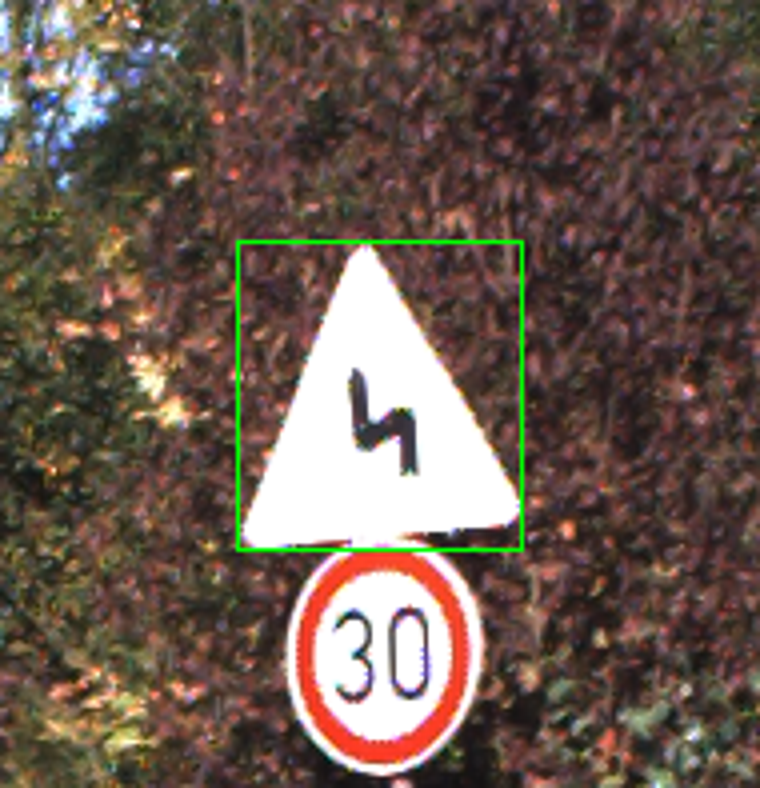

00482.png


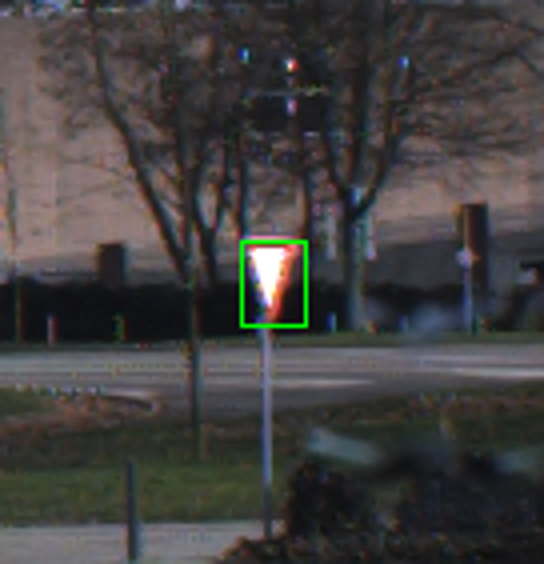

=== FALSE POSITIVES (red = predicted box) ===
00143.png  confidence 0.32


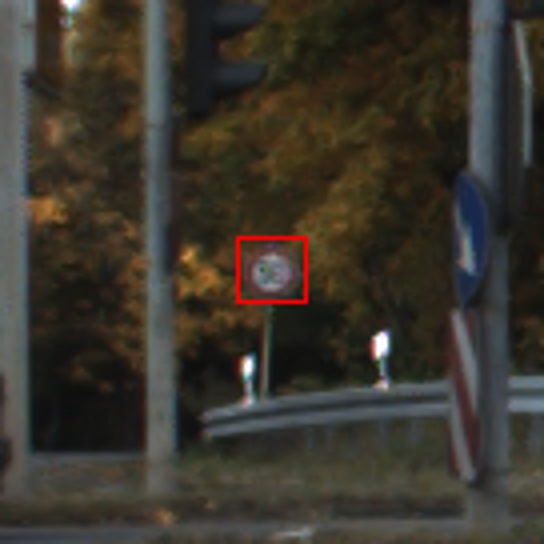

00290.png  confidence 0.30


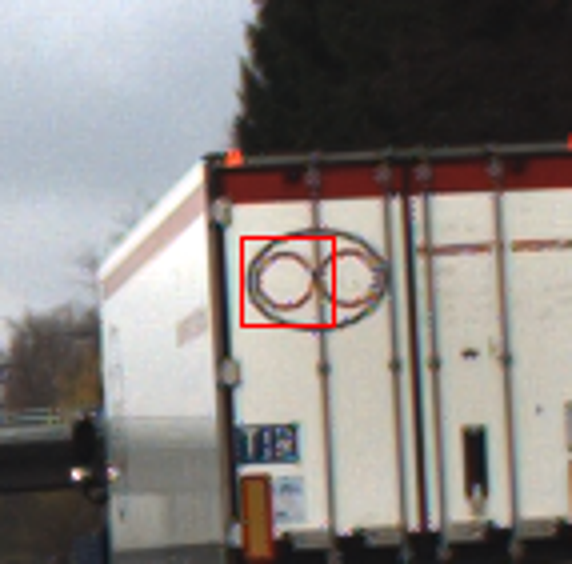

00475.png  confidence 0.36


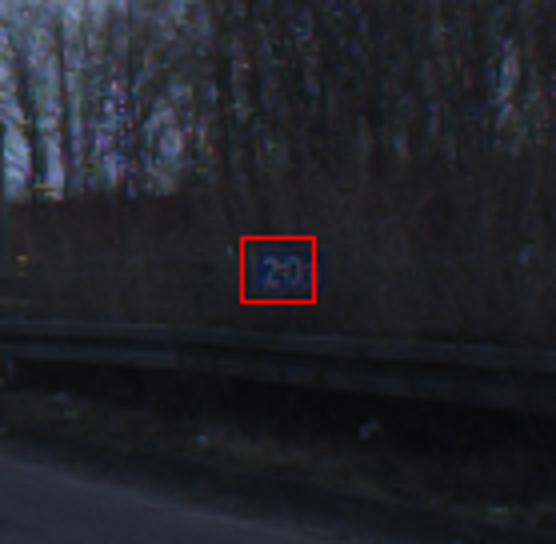

00536.png  confidence 0.82


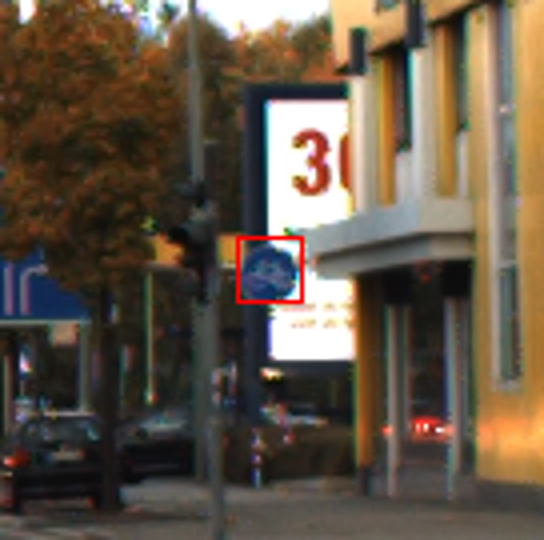

00599.png  confidence 0.48


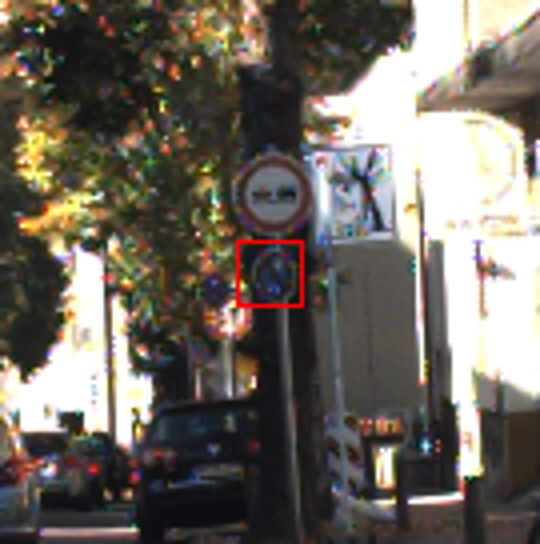

00777.png  confidence 0.61


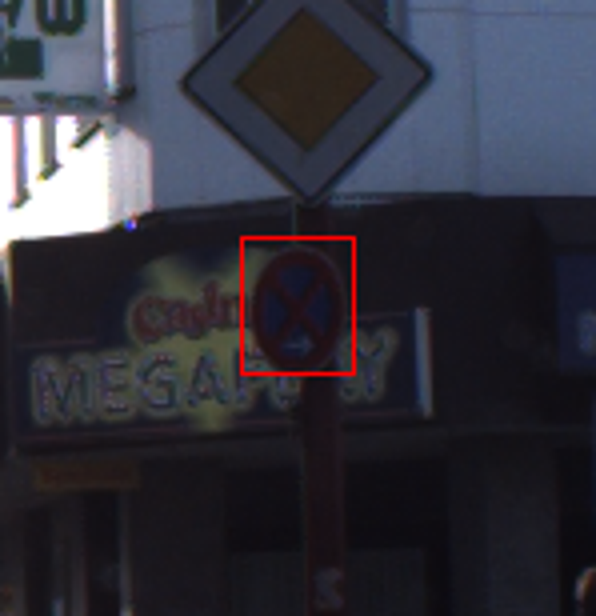

00827.png  confidence 0.36


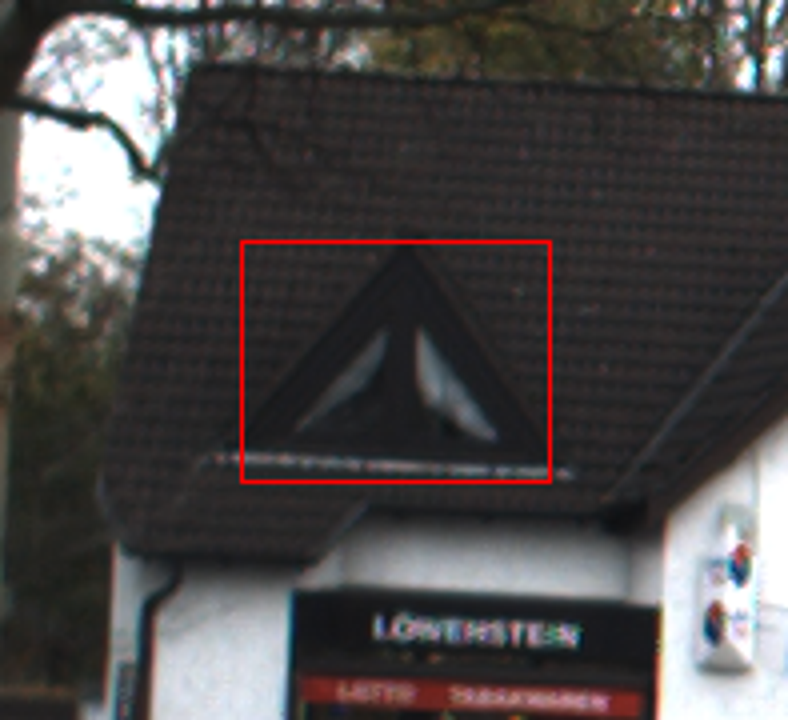

In [13]:
print("=== MISSED SIGNS (green = true box) ===")
for d in all_fn:
    print(d["image"])
    display(show_region(d["image"], d["true_box"], "lime"))

print("=== FALSE POSITIVES (red = predicted box) ===")
for d in all_fp:
    print(f"{d['image']}  confidence {d['conf']:.2f}")
    display(show_region(d["image"], d["pred_box"], "red"))

In [14]:
def analyze(model, imgsz, image_dir=VAL_IMAGES, label_dir=VAL_LABELS):
    all_tp, all_fp, all_fn = [], [], []
    for img_path in sorted(image_dir.glob("*.png")):
        label_path = label_dir / f"{img_path.stem}.txt"
        true_boxes = load_true_boxes(label_path)

        r = model.predict(img_path, imgsz=imgsz, conf=CONF, verbose=False)[0]
        pred_boxes = r.boxes.xyxy.tolist()
        pred_confs = r.boxes.conf.tolist()

        tp, fp, fn = match_boxes(true_boxes, pred_boxes, pred_confs)

        for i, j, value in tp:
            all_tp.append({"image": img_path.name, "true_box": true_boxes[j],
                           "iou": value, "conf": pred_confs[i]})
        for i in fp:
            all_fp.append({"image": img_path.name, "pred_box": pred_boxes[i],
                           "conf": pred_confs[i]})
        for j in fn:
            all_fn.append({"image": img_path.name, "true_box": true_boxes[j]})

    return all_tp, all_fp, all_fn

In [15]:
def recall_by_size(all_tp, all_fn, limit=32):
    small_found = sum(1 for d in all_tp if width(d["true_box"]) < limit)
    small_missed = sum(1 for d in all_fn if width(d["true_box"]) < limit)
    large_found = len(all_tp) - small_found
    large_missed = len(all_fn) - small_missed

    small_recall = small_found / (small_found + small_missed)
    large_recall = large_found / (large_found + large_missed)
    return small_found, small_missed, small_recall, large_found, large_missed, large_recall

In [16]:
model_640 = YOLO("../models/yolo26n_640_best.pt")
results_640 = analyze(model_640, 640)
results_1280 = analyze(model, IMGSZ)

for name, (tp, fp, fn) in [("640", results_640), ("1280", results_1280)]:
    sf, sm, sr, lf, lm, lr = recall_by_size(tp, fn)
    print(f"{name}: small {sf}/{sf + sm} = {sr:.3f} | large {lf}/{lf + lm} = {lr:.3f} | FP {len(fp)}")

640: small 53/69 = 0.768 | large 112/115 = 0.974 | FP 12
1280: small 68/69 = 0.986 | large 114/115 = 0.991 | FP 7


***Final evaluation on the test set***

In [17]:
local_yaml = DATA_DIR / "data_local.yaml"
local_yaml.write_text(f"""path: {DATA_DIR.resolve()}
train: images/train
val: images/val
test: images/test

names:
  0: sign
""")
print(local_yaml.read_text())

path: C:\Users\User\Desktop\YessinHamdi\sign-detection\data\yolo_dataset
train: images/train
val: images/val
test: images/test

names:
  0: sign



In [18]:
metrics = model.val(data=str(local_yaml), split="test", imgsz=IMGSZ, device="cpu", plots=False)
print(f"Precision: {metrics.box.mp:.3f}")
print(f"Recall:    {metrics.box.mr:.3f}")
print(f"mAP50:     {metrics.box.map50:.3f}")
print(f"mAP50-95:  {metrics.box.map:.3f}")

Ultralytics 8.4.175  Python-3.14.7 torch-2.14.1+cpu CPU (11th Gen Intel Core i7-1165G7 @ 2.80GHz)
YOLO26n summary (fused): 121 layers, 2,389,735 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access  (ping: 0.70.2 ms, read: 90.431.5 MB/s, size: 1517.6 KB)
val: Scanning C:\Users\User\Desktop\YessinHamdi\sign-detection\data\yolo_dataset\labels\test... 137 images, 25 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 137/137 225.4it/s 0.6s0.1s
val: C:\Users\User\Desktop\YessinHamdi\sign-detection\data\yolo_dataset\images\test\00340.png: 1 duplicate labels removed
val: New cache created: C:\Users\User\Desktop\YessinHamdi\sign-detection\data\yolo_dataset\labels\test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 5.1s/it 45.8s4.3ss
                   all        137        199       0.97      0.972       0.99      0.857
Speed: 4.9ms preprocess, 234.0ms inference, 0.0ms loss, 5.8ms postprocess per image
Precision: 0.970
Recall:

In [19]:
TEST_IMAGES = DATA_DIR / "images" / "test"
TEST_LABELS = DATA_DIR / "labels" / "test"

test_tp, test_fp, test_fn = analyze(model, IMGSZ, TEST_IMAGES, TEST_LABELS)
sf, sm, sr, lf, lm, lr = recall_by_size(test_tp, test_fn)

print(f"TP: {len(test_tp)}, FP: {len(test_fp)}, FN: {len(test_fn)}")
print(f"Recall: {len(test_tp) / (len(test_tp) + len(test_fn)):.3f}")
print(f"Small: {sf}/{sf + sm} = {sr:.3f} | Large: {lf}/{lf + lm} = {lr:.3f}")

TP: 196, FP: 17, FN: 4
Recall: 0.980
Small: 71/74 = 0.959 | Large: 125/126 = 0.992
